In [1]:
from pathlib import Path
from datetime import datetime
import io

import numpy as np
import pandas as pd
import requests

from sklearn.cluster import DBSCAN

ANO = 2025
SEED = 40

PROCESSADO = Path("../data/base-processada")
PROCESSADO.mkdir(parents=True, exist_ok=True)

Path("../resultados/tabelas").mkdir(parents=True, exist_ok=True)
Path("../resultados/figuras").mkdir(parents=True, exist_ok=True)


In [2]:
URL = "https://data.cityofnewyork.us/resource/h9gi-nx95.csv"


def baixar_ano(ano, tamanho_pagina=50_000):
    partes, offset = [], 0
    while True:
        params = {
            "$where": f"crash_date between '{ano}-01-01T00:00:00' and '{ano}-12-31T23:59:59'",
            "$order": "crash_date, collision_id",
            "$limit": tamanho_pagina,
            "$offset": offset,
        }
        r = requests.get(URL, params=params, timeout=120)
        r.raise_for_status()
        parte = pd.read_csv(
            io.StringIO(r.text),
            dtype={"collision_id": str, "zip_code": str},
            low_memory=False,
        )
        partes.append(parte)
        print(f"offset {offset}: {len(parte)} linhas")
        if len(parte) < tamanho_pagina:
            break
        offset += tamanho_pagina
    return pd.concat(partes, ignore_index=True)

df = baixar_ano(ANO)
print(df.shape)
print(df.columns.tolist())

offset 0: 50000 linhas
offset 50000: 35559 linhas
(85559, 29)
['crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'location', 'on_street_name', 'off_street_name', 'cross_street_name', 'number_of_persons_injured', 'number_of_persons_killed', 'number_of_pedestrians_injured', 'number_of_pedestrians_killed', 'number_of_cyclist_injured', 'number_of_cyclist_killed', 'number_of_motorist_injured', 'number_of_motorist_killed', 'contributing_factor_vehicle_1', 'contributing_factor_vehicle_2', 'contributing_factor_vehicle_3', 'contributing_factor_vehicle_4', 'contributing_factor_vehicle_5', 'collision_id', 'vehicle_type_code1', 'vehicle_type_code2', 'vehicle_type_code_3', 'vehicle_type_code_4', 'vehicle_type_code_5']


In [3]:
df["crash_date"] = pd.to_datetime(df["crash_date"], errors="coerce")

print(df["crash_date"].dt.month.value_counts().sort_index())
print("Fora de", ANO, ":", (df["crash_date"].dt.year != ANO).sum())
print("IDs duplicados:", df["collision_id"].duplicated().sum())
print("Datas inválidas:", df["crash_date"].isna().sum())
print(df.dtypes[["latitude", "longitude"]])

crash_date
1     6482
2     5988
3     7035
4     6924
5     7636
6     7486
7     7415
8     6992
9     7538
10    7538
11    7148
12    7377
Name: count, dtype: int64
Fora de 2025 : 0
IDs duplicados: 0
Datas inválidas: 0
latitude     float64
longitude    float64
dtype: object


In [4]:
print("Tem localização mas não tem lat/lon: ", (df["location"].notna() & df["latitude"].isna()).sum())

print("Tem lat/lon mas não tem localização: ", (df["location"].isna() & df["latitude"].notna()).sum())

Tem localização mas não tem lat/lon:  0
Tem lat/lon mas não tem localização:  0


In [5]:
df = df.drop(columns=["location"], errors="ignore")

funil = [("Linhas baixadas (2025)", len(df))]

d = df.dropna(subset=["latitude", "longitude"])
funil.append(("Com latitude e longitude", len(d)))

d = d[(d["latitude"] != 0) & (d["longitude"] != 0)]
funil.append(("Sem coordenadas zero", len(d)))

d = d[d["latitude"].between(40.49, 40.92) & d["longitude"].between(-74.27, -73.68)]
funil.append(("Dentro da caixa de NYC", len(d)))

funil.append(("Pontos únicos (lat, lon)",
              d[["latitude", "longitude"]].drop_duplicates().shape[0]))

tabela_funil = pd.DataFrame(funil, columns=["etapa", "linhas"])
tabela_funil["% do total"] = (tabela_funil["linhas"] / len(df) * 100).round(1)
print(tabela_funil.to_string(index=False))

df_limpo = d.reset_index(drop=True)
df_limpo.to_csv(PROCESSADO / f"colisoes_{ANO}_limpo.csv", index=False)
tabela_funil.to_csv("../resultados/tabelas/funil_volumetria.csv", index=False)

                   etapa  linhas  % do total
  Linhas baixadas (2025)   85559       100.0
Com latitude e longitude   84833        99.2
    Sem coordenadas zero   82918        96.9
  Dentro da caixa de NYC   82918        96.9
Pontos únicos (lat, lon)   44111        51.6


In [6]:
sem_nulo = df[df["latitude"].notna()]
print(((sem_nulo.latitude == 0) & (sem_nulo.longitude == 0)).sum(), "em (0, 0)")
print(((sem_nulo.latitude == 0) ^ (sem_nulo.longitude == 0)).sum(), "com só um dos dois zero")

1915 em (0, 0)
0 com só um dos dois zero


In [7]:
contagem = (df_limpo.groupby(["latitude", "longitude"])
                    .size().rename("n").reset_index())

print(contagem["n"].describe())
print(contagem["n"].value_counts().sort_index().head(10))
print((contagem["n"] >= 20).sum(), "pontos com 20 ou mais acidentes")
print(contagem.sort_values("n", ascending=False).head(10))

count    44111.000000
mean         1.879758
std          2.320013
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        169.000000
Name: n, dtype: float64
n
1     30024
2      6472
3      2992
4      1585
5       937
6       587
7       359
8       271
9       203
10      140
Name: count, dtype: int64
89 pontos com 20 ou mais acidentes
        latitude  longitude    n
3914   40.608757 -74.038086  169
3298   40.604153 -74.051980   55
41863  40.861866 -73.912740   50
18548  40.696033 -73.984530   42
14082  40.675735 -73.896850   42
18593  40.696198 -73.988760   39
12596  40.668507 -73.925606   35
35221  40.795220 -73.921524   34
35349  40.797370 -73.919810   33
13916  40.674854 -73.970780   33


In [8]:
df["sem_coord"] = (df["latitude"].isna() | (df["latitude"] == 0) | (df["longitude"] == 0))
print(df.groupby("borough", dropna=False)["sem_coord"].agg(["mean", "sum"]))

                   mean  sum
borough                     
BRONX          0.032056  394
BROOKLYN       0.025457  680
MANHATTAN      0.041345  599
QUEENS         0.027839  608
STATEN ISLAND  0.023977   75
NaN            0.040141  285


In [9]:
for m in [3, 5, 10, 20, 50]:
    q = contagem[contagem["n"] >= m]
    print(f"n >= {m:>2}: {len(q):>5} pontos | {q['n'].sum():>6} acidentes "
          f"({q['n'].sum() / len(df_limpo):.1%} das linhas)")

n >=  3:  7615 pontos |  39950 acidentes (48.2% das linhas)
n >=  5:  3038 pontos |  24634 acidentes (29.7% das linhas)
n >= 10:   681 pontos |   9919 acidentes (12.0% das linhas)
n >= 20:    89 pontos |   2443 acidentes (2.9% das linhas)
n >= 50:     3 pontos |    274 acidentes (0.3% das linhas)


In [10]:
lat, lon = contagem.loc[contagem["n"].idxmax(), ["latitude", "longitude"]]
topo = df_limpo[(df_limpo["latitude"] == lat) & (df_limpo["longitude"] == lon)]

print(topo["on_street_name"].value_counts(dropna=False).head())
print(topo["borough"].value_counts(dropna=False))
print(topo["crash_date"].dt.month.value_counts().sort_index())

on_street_name
VERRAZANO BRIDGE UPPER    137
VERRAZANO BRIDGE LOWER     32
Name: count, dtype: int64
borough
BROOKLYN    126
NaN          43
Name: count, dtype: int64
crash_date
1      9
2     11
3     15
4     20
5     14
6     16
7     26
8     21
9      9
10     9
11    11
12     8
Name: count, dtype: int64


In [11]:
top = contagem.nlargest(20, "n")

rua = (df_limpo.groupby(["latitude", "longitude"])["on_street_name"]
       .agg(lambda s: s.dropna().mode().iat[0] if s.notna().any() else None)
       .rename("rua_mais_comum").reset_index())

print(top.merge(rua, on=["latitude", "longitude"]).to_string(index=False))

 latitude  longitude   n         rua_mais_comum
40.608757 -74.038086 169 VERRAZANO BRIDGE UPPER
40.604153 -74.051980  55 VERRAZANO BRIDGE UPPER
40.861866 -73.912740  50           W FORDHAM RD
40.675735 -73.896850  42       PENNSYLVANIA AVE
40.696033 -73.984530  42             TILLARY ST
40.696198 -73.988760  39               ADAMS ST
40.668507 -73.925606  35           EASTERN PKWY
40.795220 -73.921524  34      TRIBOROUGH BRIDGE
40.642540 -73.876520  33           BELT PARKWAY
40.658577 -73.890625  33       PENNSYLVANIA AVE
40.674854 -73.970780  33           FLATBUSH AVE
40.711220 -73.728264  33      CROSS ISLAND PKWY
40.795370 -73.921974  33      TRIBOROUGH BRIDGE
40.797370 -73.919810  33      TRIBOROUGH BRIDGE
40.749470 -73.756400  32 LONG ISLAND EXPRESSWAY
40.820190 -73.890680  32          BRUCKNER BLVD
40.704494 -73.817430  31         VAN WYCK EXPWY
40.813095 -73.898260  31          BRUCKNER BLVD
40.848120 -73.930885  31               W 181 ST
40.749283 -73.756645  30 LONG ISLAND EXP

k=5: mediana 58 m | p75 92 m | p90 141 m | % com distância 0: 29.7%
k=10: mediana 100 m | p75 155 m | p90 209 m | % com distância 0: 12.0%
k=20: mediana 165 m | p75 228 m | p90 299 m | % com distância 0: 2.9%


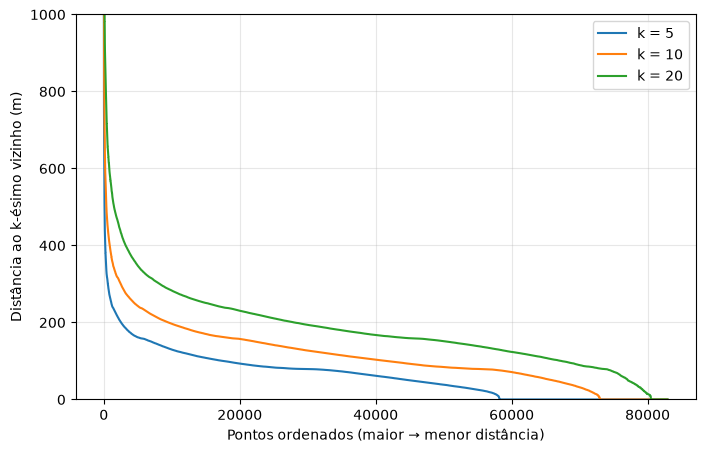

In [12]:
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

X = np.radians(df_limpo[["latitude", "longitude"]].to_numpy())
R = 6_371_000

fig, ax = plt.subplots(figsize=(8, 5))
for k in [5, 10, 20]:
    nn = NearestNeighbors(n_neighbors=k, metric="haversine", algorithm="ball_tree").fit(X)
    dist, _ = nn.kneighbors(X)
    kdist = np.sort(dist[:, -1] * R)[::-1]
    ax.plot(kdist, label=f"k = {k}")
    print(f"k={k}: mediana {np.median(kdist):.0f} m | "
          f"p75 {np.percentile(kdist, 75):.0f} m | p90 {np.percentile(kdist, 90):.0f} m | "
          f"% com distância 0: {(kdist == 0).mean():.1%}")

ax.set_ylim(0, 1000)
ax.set_xlabel("Pontos ordenados (maior → menor distância)")
ax.set_ylabel("Distância ao k-ésimo vizinho (m)")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig("../resultados/figuras/kdistancia.png", dpi=150, bbox_inches="tight")

In [13]:
kdists = {}
for k in [5, 10, 20]:
    nn = NearestNeighbors(n_neighbors=k, metric="haversine", algorithm="ball_tree").fit(X)
    dist, _ = nn.kneighbors(X)
    kdists[k] = dist[:, -1] * R

for k, d in kdists.items():
    frac = {e: f"{(d <= e).mean():.0%}" for e in [50, 100, 150, 250, 400]}
    print(f"k={k}: centrais por eps {frac} | p99: {np.percentile(d, 99):.0f} m | máx: {d.max():.0f} m")

k=5: centrais por eps {50: '46%', 100: '79%', 150: '92%', 250: '99%', 400: '100%'} | p99: 272 m | máx: 1640 m
k=10: centrais por eps {50: '20%', 100: '50%', 150: '73%', 250: '95%', 400: '99%'} | p99: 406 m | máx: 2643 m
k=20: centrais por eps {50: '7%', 100: '19%', 150: '39%', 250: '82%', 400: '96%'} | p99: 595 m | máx: 2829 m


In [14]:
Xp = np.radians(contagem[["latitude", "longitude"]].to_numpy())
w = contagem["n"].to_numpy()

linhas = []
for min_s in [5, 10, 20]:
    for eps_m in [50, 100, 150, 250, 400]:
        lab = DBSCAN(eps=eps_m / R, min_samples=min_s,
                     metric="haversine", algorithm="ball_tree").fit(Xp, sample_weight=w).labels_
        tam = pd.Series(w[lab != -1]).groupby(lab[lab != -1]).sum()   # acidentes por cluster
        linhas.append({
            "min_samples": min_s, "eps_m": eps_m,
            "n_clusters": len(tam),
            "pct_ruido": round(w[lab == -1].sum() / w.sum() * 100, 1),
            "pct_maior_cluster": round(tam.max() / w.sum() * 100, 1) if len(tam) else 0,
            "tamanho_mediano": tam.median() if len(tam) else 0,
        })

grade = pd.DataFrame(linhas)
print(grade.to_string(index=False))
grade.to_csv("../resultados/tabelas/grade_dbscan.csv", index=False)

 min_samples  eps_m  n_clusters  pct_ruido  pct_maior_cluster  tamanho_mediano
           5     50        4311       50.1                0.2              7.0
           5    100        2499       13.7               11.7              9.0
           5    150         829        4.7               36.2              9.0
           5    250         144        0.6               58.8             10.0
           5    400          25        0.1               92.9              9.0
          10     50        1171       76.2                0.2             13.0
          10    100        1620       35.7                3.7             17.0
          10    150         691       15.0               24.7             18.0
          10    250         117        2.3               57.4             18.0
          10    400          25        0.4               92.8             31.0
          20     50         234       91.6                0.2             26.0
          20    100         608       70.4          

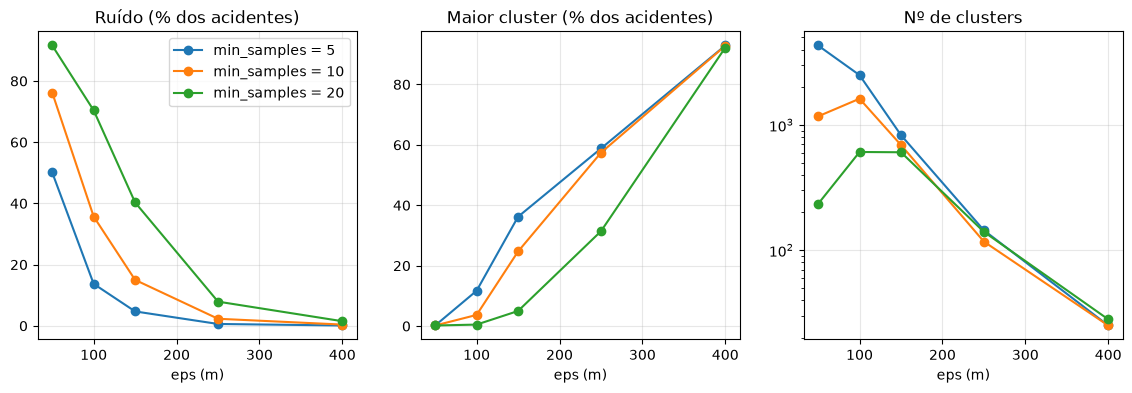

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for k, g in grade.groupby("min_samples"):
    axs[0].plot(g.eps_m, g.pct_ruido, marker="o", label=f"min_samples = {k}")
    axs[1].plot(g.eps_m, g.pct_maior_cluster, marker="o")
    axs[2].plot(g.eps_m, g.n_clusters, marker="o")
for ax, t in zip(axs, ["Ruído (% dos acidentes)", "Maior cluster (% dos acidentes)", "Nº de clusters"]):
    ax.set_title(t); ax.set_xlabel("eps (m)"); ax.grid(alpha=0.3)
axs[2].set_yscale("log")
axs[0].legend()
fig.savefig("../resultados/figuras/grade_eps_minsamples.png", dpi=150, bbox_inches="tight")

In [16]:
def resumo_clusters(min_s, eps_m):
    lab = DBSCAN(eps=eps_m / R, min_samples=min_s, metric="haversine",
                 algorithm="ball_tree").fit(Xp, sample_weight=w).labels_
    ok = contagem.assign(cluster=lab)
    ok = ok[ok.cluster != -1].assign(wl=lambda d: d.latitude * d.n,
                                     wo=lambda d: d.longitude * d.n)
    r = ok.groupby("cluster").agg(
        acidentes=("n", "sum"), pontos_unicos=("n", "size"),
        lat_min=("latitude", "min"), lat_max=("latitude", "max"),
        lon_min=("longitude", "min"), lon_max=("longitude", "max"),
        wl=("wl", "sum"), wo=("wo", "sum"))
    r["lat"] = r.wl / r.acidentes
    r["lon"] = r.wo / r.acidentes
    r["extensao_m"] = np.hypot((r.lat_max - r.lat_min) * 111_000,
                               (r.lon_max - r.lon_min) * 111_000 * np.cos(np.radians(r.lat)))
    return lab, r.drop(columns=["wl", "wo"]).sort_values("acidentes", ascending=False)

labA, resA = resumo_clusters(10, 100)
labB, resB = resumo_clusters(20, 150)
print(resB.head(15).round(1).to_string())
print("Clusters de 1 único ponto (B):", (resB.pontos_unicos == 1).mean().round(3))

         acidentes  pontos_unicos  lat_min  lat_max  lon_min  lon_max   lat   lon  extensao_m
cluster                                                                                      
351           4142           1906     40.7     40.8    -74.0    -74.0  40.8 -74.0      6851.7
466           2141            931     40.8     40.8    -74.0    -73.9  40.8 -73.9      5037.8
283           2018           1120     40.7     40.7    -74.0    -74.0  40.7 -74.0      4895.3
189           1828            735     40.7     40.7    -74.0    -74.0  40.7 -74.0      4484.2
128            921            376     40.7     40.7    -73.9    -73.9  40.7 -73.9      3115.7
550            900            347     40.8     40.9    -73.9    -73.9  40.8 -73.9      3501.6
568            785            368     40.9     40.9    -73.9    -73.9  40.9 -73.9      2798.6
236            753            337     40.7     40.7    -74.0    -73.9  40.7 -73.9      3732.3
491            682            296     40.8     40.8    -73.9

In [17]:
mapa_lab = contagem[["latitude", "longitude"]].assign(cluster=labB)
tmp = df_limpo.merge(mapa_lab, on=["latitude", "longitude"], how="left")
tmp = tmp[tmp["cluster"] != -1].astype({"cluster": int})

vias = (tmp.groupby("cluster")["on_street_name"]
           .agg(lambda s: s.value_counts().head(3).index.tolist()))
resB["vias_principais"] = vias        # sem arredondar o resB

exibir = resB.head(15)[["acidentes", "pontos_unicos", "lat", "lon",
                        "extensao_m", "vias_principais"]]
print(exibir.round({"lat": 5, "lon": 5, "extensao_m": 0}).to_string())

         acidentes  pontos_unicos       lat       lon  extensao_m                                           vias_principais
cluster                                                                                                                    
351           4142           1906  40.75379 -73.98236      6852.0                                   [2 AVE, W 42 ST, 3 AVE]
466           2141            931  40.79931 -73.94296      5038.0                           [FDR DRIVE, E 125 ST, W 125 ST]
283           2018           1120  40.72027 -73.99840      4895.0                     [CANAL ST, DELANCEY ST, E HOUSTON ST]
189           1828            735  40.68634 -73.98703      4484.0  [BROOKLYN QUEENS EXPRESSWAY, FLATBUSH AVE, ATLANTIC AVE]
128            921            376  40.66419 -73.92812      3116.0                [UTICA AVE, EASTERN PKWY, SCHENECTADY AVE]
550            900            347  40.84681 -73.92487      3502.0                  [CROSS BRONX EXPY, JEROME AVE, BROADWAY]
568     

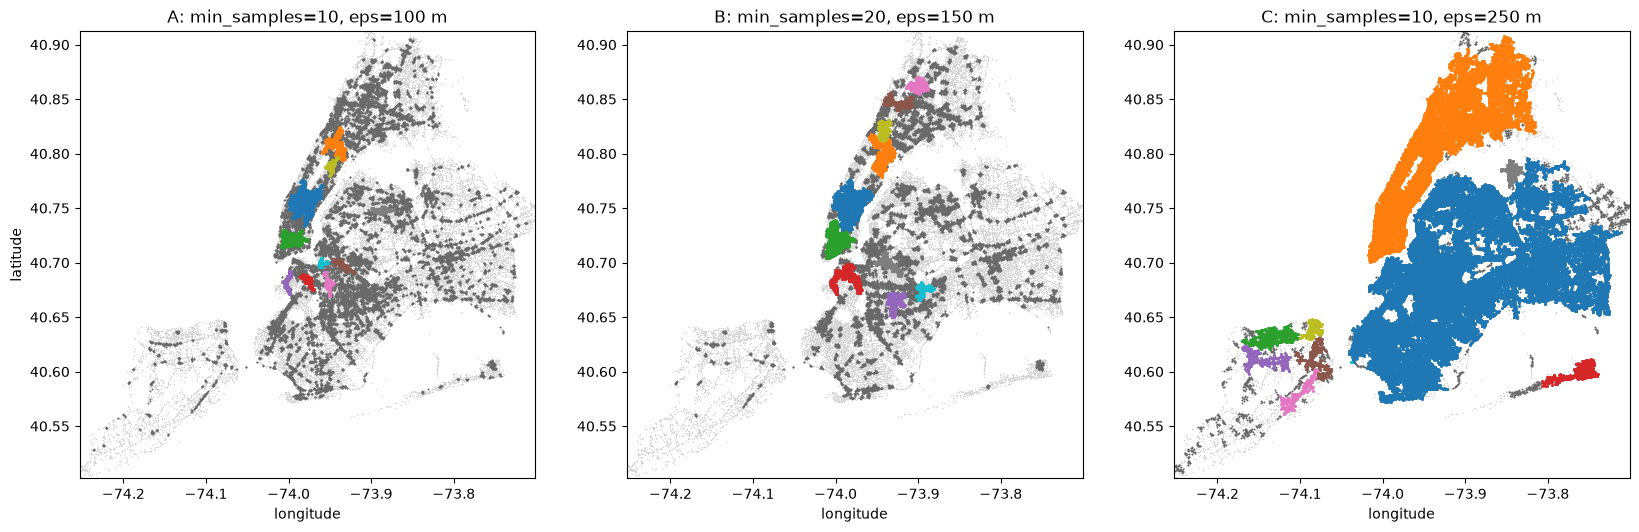

In [18]:
labC, resC = resumo_clusters(10, 250)

def plotar(ax, lab, res, titulo, top=10):
    ruido = lab == -1
    top_ids = res.index[:top]
    outros = (~ruido) & (~np.isin(lab, top_ids))

    ax.scatter(contagem.longitude[ruido], contagem.latitude[ruido],
               s=1, c="lightgray", linewidths=0)
    ax.scatter(contagem.longitude[outros], contagem.latitude[outros],
               s=2, c="dimgray", linewidths=0)
    for cor, cid in zip(plt.cm.tab10(np.arange(top)), top_ids):
        m = lab == cid
        ax.scatter(contagem.longitude[m], contagem.latitude[m],
                   s=5, color=cor, linewidths=0)

    ax.set_title(titulo)
    ax.set_xlim(contagem.longitude.min(), contagem.longitude.max())
    ax.set_ylim(contagem.latitude.min(), contagem.latitude.max())
    ax.set_aspect(1 / np.cos(np.radians(40.73)))
    ax.set_xlabel("longitude")

fig, axs = plt.subplots(1, 3, figsize=(20, 8))
plotar(axs[0], labA, resA, "A: min_samples=10, eps=100 m")
plotar(axs[1], labB, resB, "B: min_samples=20, eps=150 m")
plotar(axs[2], labC, resC, "C: min_samples=10, eps=250 m")
axs[0].set_ylabel("latitude")

fig.savefig("../resultados/figuras/mapas_abc.png", dpi=150, bbox_inches="tight")